# Data Augmentation with `torchvision.transforms.v2`
### Representation Learning, Lecture 3: MNIST / Fashion-MNIST

> Based on Lightning AI's *Deep Learning Fundamentals*, Unit 7.5 Part 2 (Sebastian Raschka) ([video](https://www.youtube.com/watch?v=DY905WdWv_M)), adapted from CIFAR-10 / transforms v1 to MNIST / transforms v2.

Augmentation draws a random transformation $t\sim\mathcal{T}$ every time an image is loaded, so we train on

$$
\min_\theta\;\frac{1}{N}\sum_{n=1}^{N}\mathbb{E}_{t\sim\mathcal{T}}\big[\ell\big(f_\theta(t(x_n)),\,y_n\big)\big].
$$

By choosing $\mathcal{T}$ we decide which changes should **not** change the prediction: $f_\theta(t(x))\approx f_\theta(x)$.

## 1. Setup and data

In [1]:
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import torchvision
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import v2

torch.manual_seed(42)

In [20]:
DATASET = datasets.MNIST    # or: datasets.FashionMNIST

to_tensor = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])   # image -> float tensor in [0, 1]
train_dataset = DATASET(root="./data", train=True, download=True, transform=to_tensor)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

images, labels = next(iter(train_loader)) # get a batch of images and labels
print(images.shape)

torch.Size([64, 1, 28, 28])


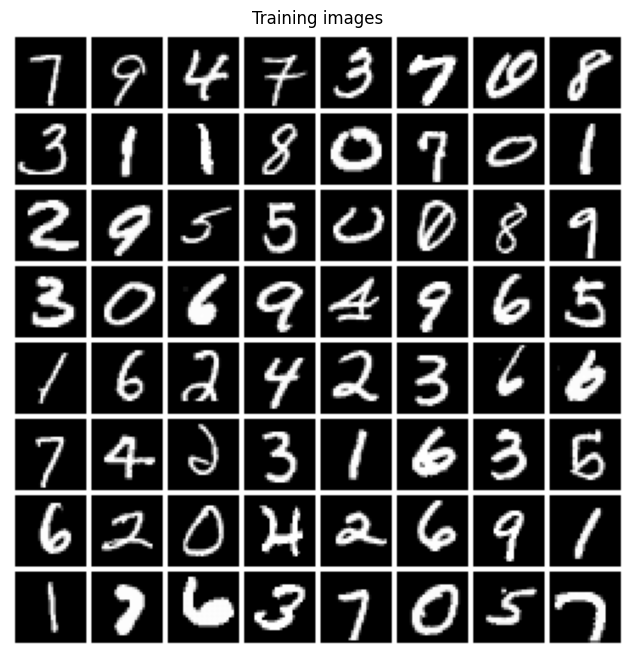

In [21]:
plt.figure(figsize=(8, 8))
plt.axis("off")
plt.title("Training images")
plt.imshow(torchvision.utils.make_grid(images[:64], padding=2, pad_value=1.0, normalize=True).permute(1, 2, 0)) # permute to (H, W, C) from (C, H, W)
plt.show()

## 2. Normalization statistics
`Normalize` computes $\hat{x}=(x-\mu)/\sigma$. The video used $\mu=\sigma=0.5$. Here we compute $\mu$ and $\sigma$ over all training pixels.

In [4]:
MEAN = (train_dataset.data / 255).mean()
STD = (train_dataset.data / 255).std()
print(f"mean = {MEAN:.4f}, std = {STD:.4f}")

mean = 0.1307, std = 0.3081


## 3. Custom data transform (the video's pipeline in v2)

| Video (v1, CIFAR-10) | Here (v2, MNIST 28×28) |
|---|---|
| `ToPILImage()` | not needed: v2 works on tensors |
| `Resize((150, 150))` → `RandomCrop((128, 128))` | `Resize((32, 32))` → `RandomCrop((28, 28))` |
| `RandomHorizontalFlip(p=0.2)` | removed: a mirrored digit is not a digit (fine for Fashion-MNIST) |
| `ColorJitter(brightness, contrast, saturation, hue)` | `ColorJitter(brightness, contrast)`: no color in grayscale |
| `ToTensor()` | `ToImage()` + `ToDtype(torch.float32, scale=True)` |
| `Normalize((0.5,)*3, (0.5,)*3)` | `Normalize((MEAN,), (STD,))` |

In [5]:
train_transform = v2.Compose([
    v2.ToImage(),
    v2.Resize((32, 32)),
    v2.RandomCrop((28, 28)),
    # v2.RandomHorizontalFlip(p=0.5),    # OK for FashionMNIST, NOT for digits
    v2.ColorJitter(brightness=0.8, contrast=0.1),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((MEAN,), (STD,)),
])

test_transform = v2.Compose([
    v2.ToImage(),
    v2.Resize((32, 32)),
    v2.CenterCrop((28, 28)),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((MEAN,), (STD,)),
])

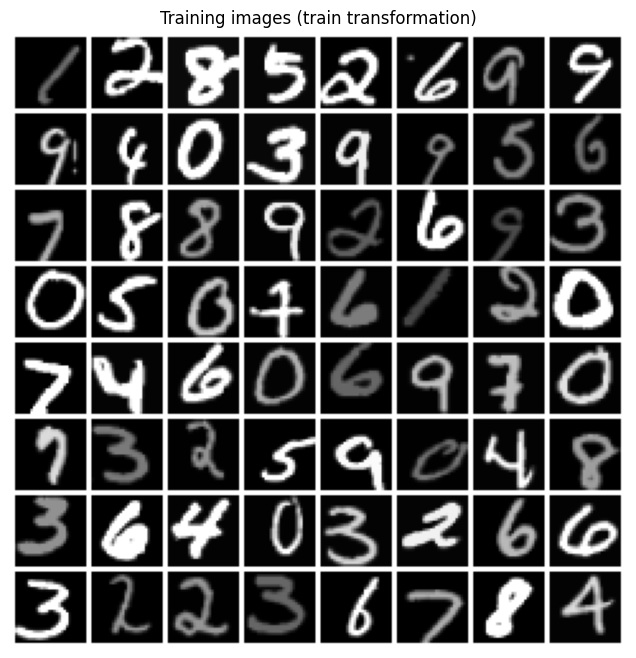

In [6]:
transformed = [train_transform(img) for img in images]

plt.figure(figsize=(8, 8))
plt.axis("off")
plt.title("Training images (train transformation)")
plt.imshow(torchvision.utils.make_grid(transformed[:64], padding=2, pad_value=1.0, normalize=True).permute(1, 2, 0))
plt.show()

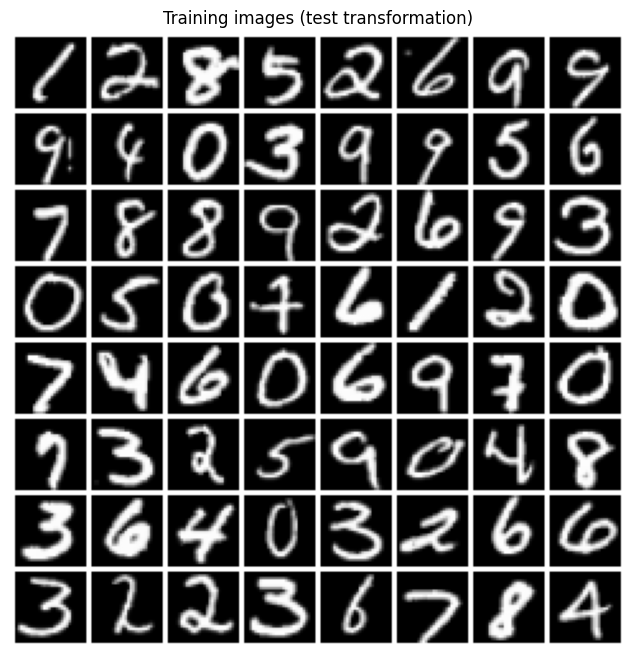

In [7]:
transformed = [test_transform(img) for img in images]

plt.figure(figsize=(8, 8))
plt.axis("off")
plt.title("Training images (test transformation)")
plt.imshow(torchvision.utils.make_grid(transformed[:64], padding=2, pad_value=1.0, normalize=True).permute(1, 2, 0))
plt.show()

**Why one image at a time?** Called on a whole batch, a v2 transform draws **one** random parameter set and applies it to all images.
Inside a `Dataset`, the transform is called once per sample, so every image gets its own random draw.

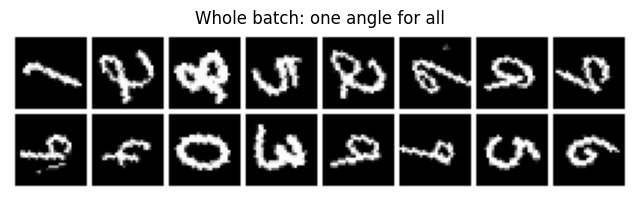

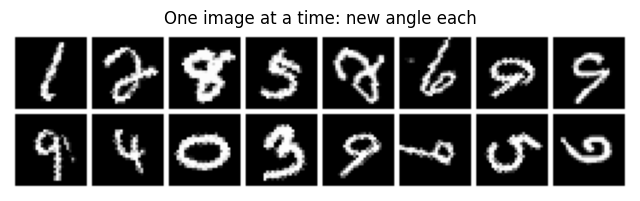

In [8]:
rotate = v2.RandomRotation(degrees=90)

for title, rotated in [("Whole batch: one angle for all", rotate(images[:16])),
                       ("One image at a time: new angle each", [rotate(img) for img in images[:16]])]:
    plt.figure(figsize=(8, 2.5))
    plt.axis("off")
    plt.title(title)
    plt.imshow(torchvision.utils.make_grid(rotated, padding=2, pad_value=1.0, normalize=True).permute(1, 2, 0)) # permute to HWC for matplotlib, from CHW
    plt.show()

## 4. More augmentations

### Geometric
* Affine: a pixel at $\mathbf{p}$ moves to $\mathbf{p}'=A\mathbf{p}+\mathbf{b}$ ($A$ combines rotation, scale and shear; $\mathbf{b}$ is translation).
* Elastic (Simard et al., 2003, proposed for MNIST): a smooth random displacement field $\Delta=\alpha\,(G_\sigma*U)$ gives $x'(\mathbf{p})=x(\mathbf{p}+\Delta(\mathbf{p}))$.

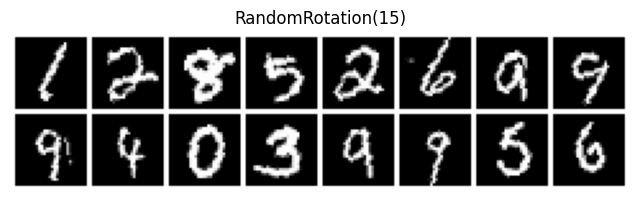

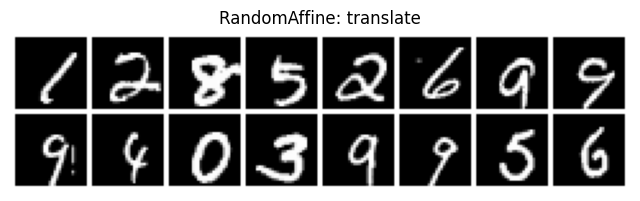

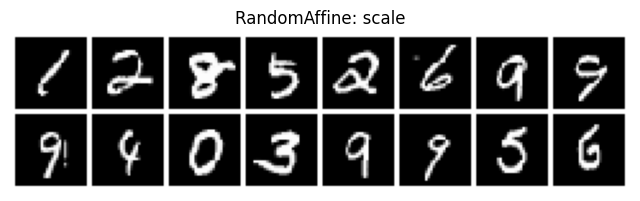

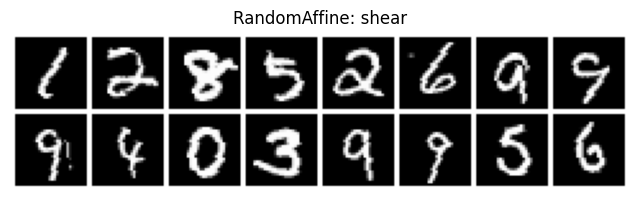

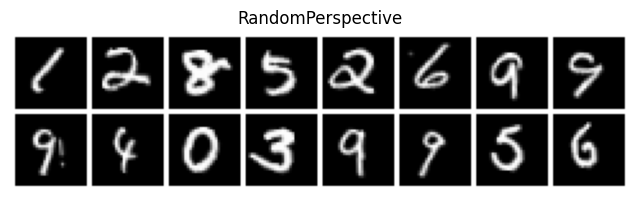

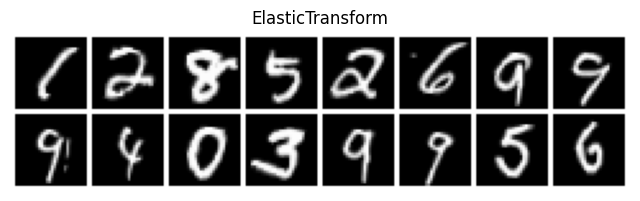

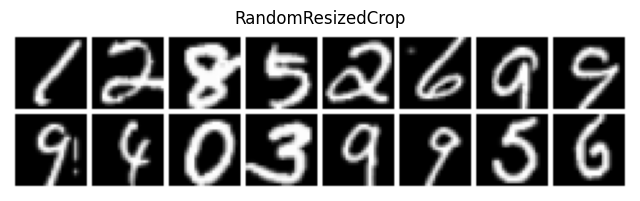

In [9]:
geometric = {
    "RandomRotation(15)": v2.RandomRotation(degrees=15),
    "RandomAffine: translate": v2.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    "RandomAffine: scale": v2.RandomAffine(degrees=0, scale=(0.8, 1.2)),
    "RandomAffine: shear": v2.RandomAffine(degrees=0, shear=20),
    "RandomPerspective": v2.RandomPerspective(distortion_scale=0.4, p=1.0),
    "ElasticTransform": v2.ElasticTransform(alpha=30.0, sigma=4.0),
    "RandomResizedCrop": v2.RandomResizedCrop(28, scale=(0.5, 1.0)),
}

for name, aug in geometric.items():
    augmented = [img for img in aug(images[:16])]
    plt.figure(figsize=(8, 2.5))
    plt.axis("off")
    plt.title(name)
    plt.imshow(torchvision.utils.make_grid(augmented, padding=2, pad_value=1.0, normalize=True).permute(1, 2, 0))
    plt.show()

### Photometric and occlusion
* Brightness $x'=b\,x$; contrast $x'=c\,x+(1-c)\bar{x}$; blur $x'=G_\sigma*x$; invert $x'=1-x$; solarize inverts pixels above a threshold.
* `RandomErasing` (Cutout) hides a random rectangle, so the model has to use the whole object.

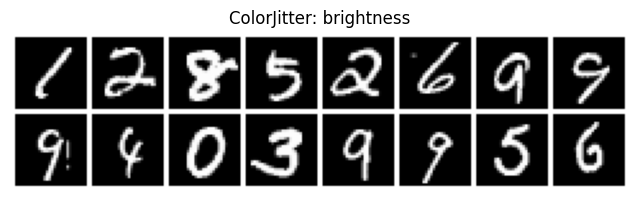

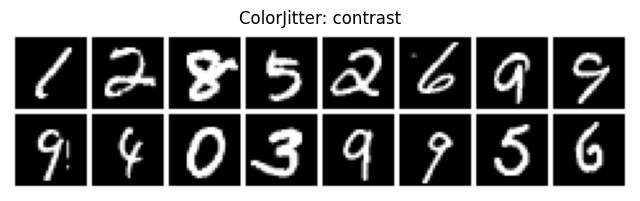

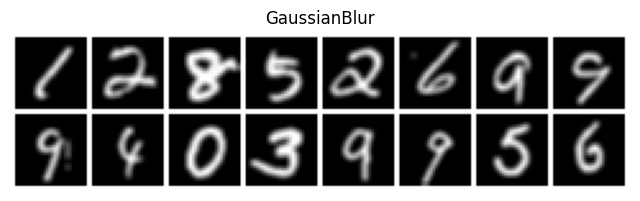

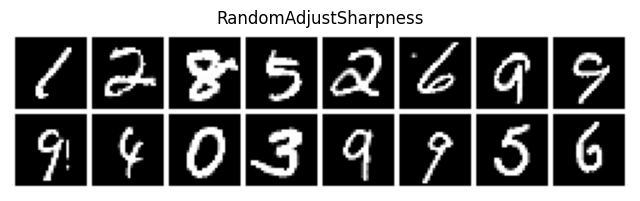

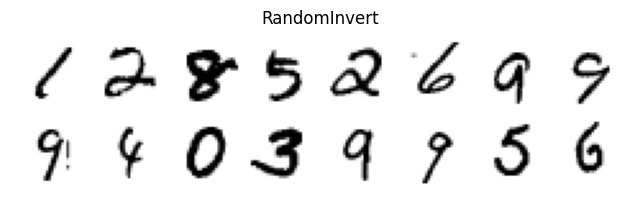

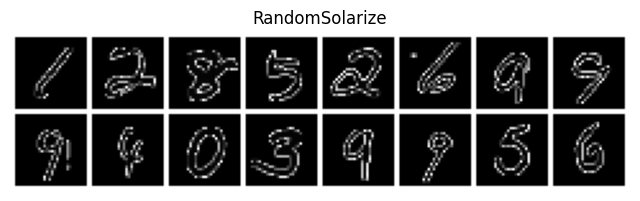

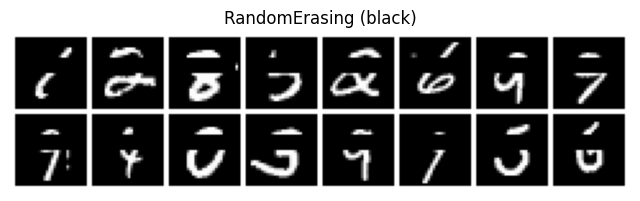

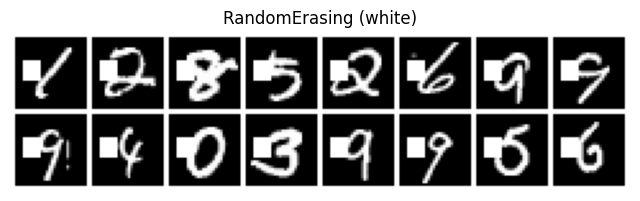

In [10]:
photometric = {
    "ColorJitter: brightness": v2.ColorJitter(brightness=0.5),
    "ColorJitter: contrast": v2.ColorJitter(contrast=0.5),
    "GaussianBlur": v2.GaussianBlur(kernel_size=3, sigma=(0.1, 1.5)),
    "RandomAdjustSharpness": v2.RandomAdjustSharpness(sharpness_factor=3, p=1.0),
    "RandomInvert": v2.RandomInvert(p=1.0),
    "RandomSolarize": v2.RandomSolarize(threshold=0.5, p=1.0),
    "RandomErasing (black)": v2.RandomErasing(p=1.0, scale=(0.05, 0.2), value=0),
    "RandomErasing (white)": v2.RandomErasing(p=1.0, scale=(0.02, 0.1), value=1),
}

for name, aug in photometric.items():
    augmented = [img for img in aug(images[:16])]
    plt.figure(figsize=(8, 2.5))
    plt.axis("off")
    plt.title(name)
    plt.imshow(torchvision.utils.make_grid(augmented, padding=2, pad_value=1.0, normalize=True).permute(1, 2, 0))
    plt.show()

### Automatic policies
These choose the operations for you. AutoAugment uses a learned policy; torchvision includes one for SVHN digits. RandAugment applies $N$ random ops with magnitude $M$. TrivialAugment applies 1 random op with a random magnitude. AugMix mixes several augmentation chains.
They were designed for color photos, so some ops can be too strong for digits (e.g. large rotations).

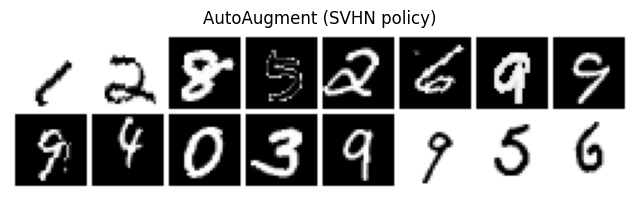

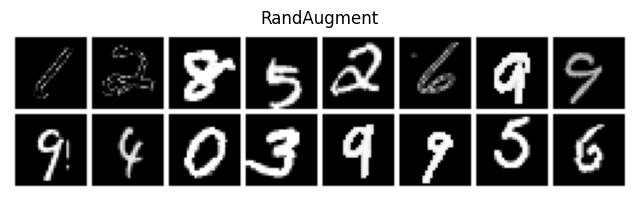

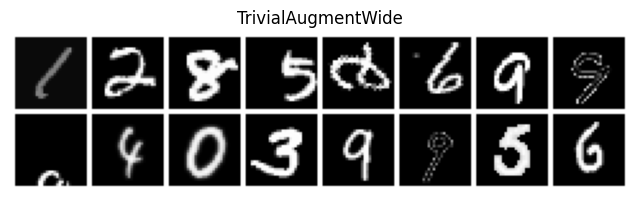

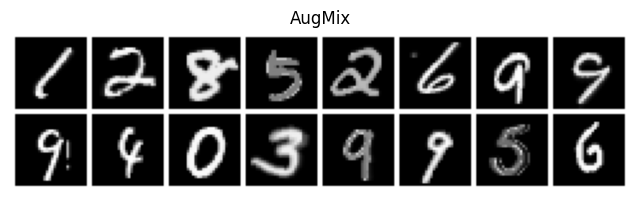

In [11]:
automatic = {
    "AutoAugment (SVHN policy)": v2.AutoAugment(v2.AutoAugmentPolicy.SVHN),
    "RandAugment": v2.RandAugment(num_ops=2, magnitude=9),
    "TrivialAugmentWide": v2.TrivialAugmentWide(),
    "AugMix": v2.AugMix(),
}

for name, aug in automatic.items():
    augmented = [aug(img) for img in images[:16]]
    plt.figure(figsize=(8, 2.5))
    plt.axis("off")
    plt.title(name)
    plt.imshow(torchvision.utils.make_grid(augmented, padding=2, pad_value=1.0, normalize=True).permute(1, 2, 0))
    plt.show()

## 5. Is the augmentation label-preserving?
An augmentation is only valid if it does not change the label: $y(t(x))=y(x)$.
For MNIST, flips and large rotations break this; a rotated **6** becomes a **9**. For Fashion-MNIST, a horizontal flip is fine.
Switch `DATASET` and compare.

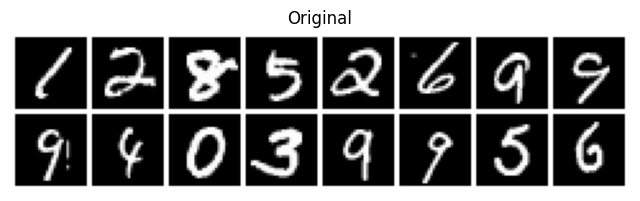

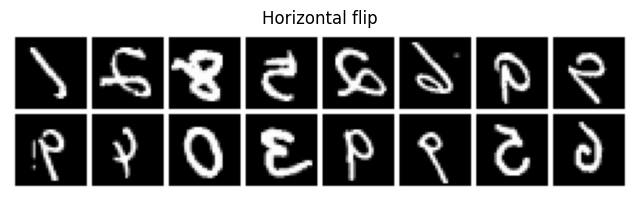

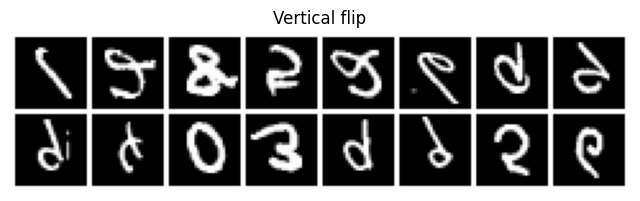

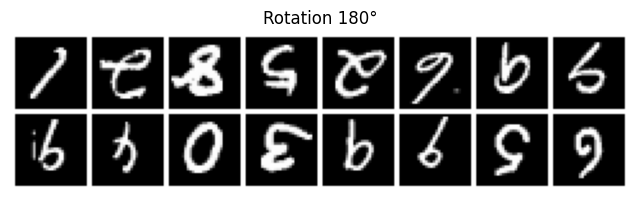

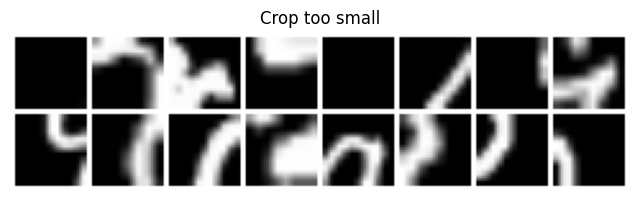

In [12]:
label_check = {
    "Original": v2.Identity(),
    "Horizontal flip": v2.RandomHorizontalFlip(p=1.0),
    "Vertical flip": v2.RandomVerticalFlip(p=1.0),
    "Rotation 180°": v2.RandomRotation(degrees=(180, 180)),
    "Crop too small": v2.RandomResizedCrop(28, scale=(0.05, 0.15)),
}

for name, aug in label_check.items():
    augmented = [aug(img) for img in images[:16]]
    plt.figure(figsize=(8, 2.5))
    plt.axis("off")
    plt.title(name)
    plt.imshow(torchvision.utils.make_grid(augmented, padding=2, pad_value=1.0, normalize=True).permute(1, 2, 0))
    plt.show()

## 6. Custom augmentations: inheriting from `v2.Transform`
Subclass `v2.Transform` and override `transform(self, inpt, params)`, which receives one image and returns the augmented image (torchvision ≥ 0.21; older versions call it `_transform`).
Our transforms expect float images in $[0,1]$, so place them **after** `ToDtype` and **before** `Normalize`.

* **Gaussian noise:** $x'=\operatorname{clip}(x+\epsilon,\,0,\,1)$, with $\epsilon\sim\mathcal{N}(0,\sigma^2)$
* **Salt and pepper:** a fraction $a$ of the pixels is set to 0 (pepper) or 1 (salt)
* **Stroke width:** dilation $\max_{(u,v)\in B}x(i+u,j+v)$ thickens strokes, and erosion ($\min$) thins them; both are a stride-1 max-pool

In [13]:
class GaussianNoise(v2.Transform):
    def __init__(self, sigma=0.1):
        super().__init__()
        self.sigma = sigma

    def _transform(self, inpt, params):
        return (inpt + self.sigma * torch.randn_like(inpt)).clamp(0, 1)


class SaltAndPepper(v2.Transform):
    def __init__(self, amount=0.05):
        super().__init__()
        self.amount = amount

    def _transform(self, inpt, params):
        noise = torch.rand_like(inpt)
        out = inpt.clone()
        out[noise < self.amount / 2] = 0.0          # pepper
        out[noise > 1 - self.amount / 2] = 1.0      # salt
        return out


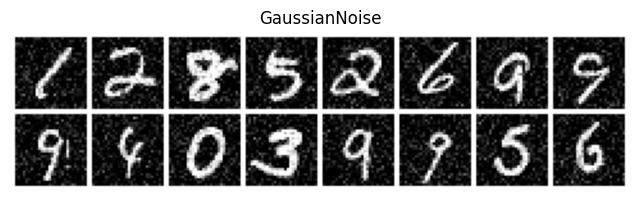

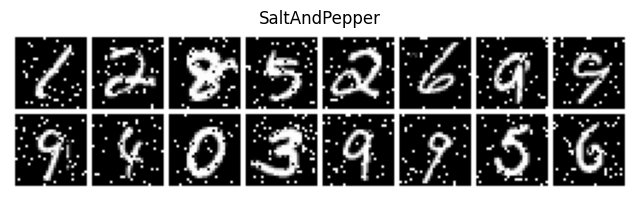

In [14]:
custom = {
    "GaussianNoise": GaussianNoise(sigma=0.15),
    "SaltAndPepper": SaltAndPepper(amount=0.1),
}

for name, aug in custom.items():
    augmented = [aug(img) for img in images[:16]]
    plt.figure(figsize=(8, 2.5))
    plt.axis("off")
    plt.title(name)
    plt.imshow(torchvision.utils.make_grid(augmented, padding=2, pad_value=1.0, normalize=True).permute(1, 2, 0))
    plt.show()

Custom transforms combine with built-in ones like any other transform:

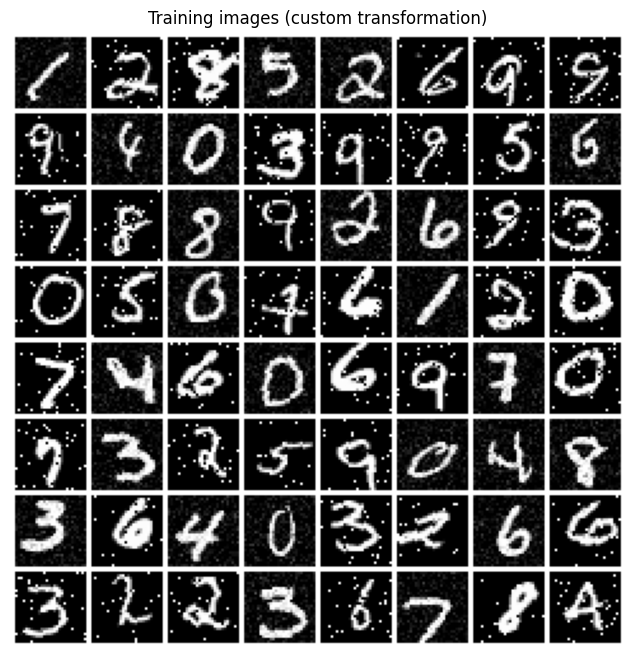

In [15]:
custom_transform = v2.Compose([
    v2.ToImage(),
    v2.RandomAffine(degrees=10, translate=(0.1, 0.1)),
    v2.ToDtype(torch.float32, scale=True),
    v2.RandomChoice([GaussianNoise(sigma=0.1), SaltAndPepper(amount=0.05)]),
    v2.Normalize((MEAN,), (STD,)),
])

transformed = [custom_transform(img) for img in images]

plt.figure(figsize=(8, 8))
plt.axis("off")
plt.title("Training images (custom transformation)")
plt.imshow(torchvision.utils.make_grid(transformed[:64], padding=2, pad_value=1.0, normalize=True).permute(1, 2, 0))
plt.show()

## 7. MixUp and CutMix (batch-level)
These mix **two** images and their labels, so they are applied to a whole batch:
* **MixUp:** $\tilde{x}=\lambda x_i+(1-\lambda)x_j$ and $\tilde{y}=\lambda y_i+(1-\lambda)y_j$, with $\lambda\sim\text{Beta}(\alpha,\alpha)$
* **CutMix:** paste a random box of $x_j$ into $x_i$; $\lambda$ is the fraction of the image that comes from $x_i$

The labels become soft (probabilities); `F.cross_entropy` accepts them as targets.

MixUp label of first image: tensor([0.0000, 0.5600, 0.0000, 0.0000, 0.0000, 0.0000, 0.4400, 0.0000, 0.0000,
        0.0000])


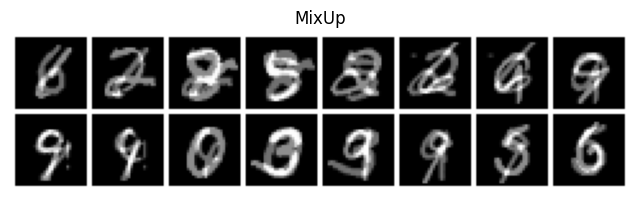

CutMix label of first image: tensor([0.0000, 0.7800, 0.0000, 0.0000, 0.0000, 0.0000, 0.2200, 0.0000, 0.0000,
        0.0000])


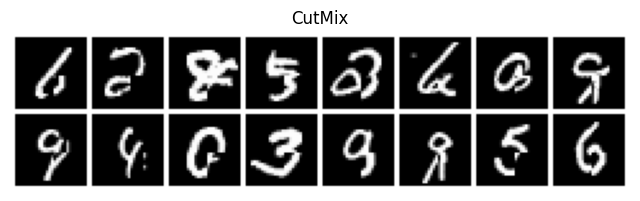

In [16]:
torch.manual_seed(42)
mixup = v2.MixUp(alpha=1.0, num_classes=10)
cutmix = v2.CutMix(alpha=1.0, num_classes=10)

for name, mix in [("MixUp", mixup), ("CutMix", cutmix)]:
    mixed_images, mixed_labels = mix(images[:16], labels[:16])
    print(name, "label of first image:", mixed_labels[0].round(decimals=2))
    plt.figure(figsize=(8, 2.5))
    plt.axis("off")
    plt.title(name)
    plt.imshow(torchvision.utils.make_grid(mixed_images, padding=2, pad_value=1.0, normalize=True).permute(1, 2, 0))
    plt.show()

## 8. Toward self-supervised learning: two views of the same image
Without labels, augmentation *is* the training signal. Two random views $\tilde{x}^{(1)}=t_1(x)$ and $\tilde{x}^{(2)}=t_2(x)$, with $t_1,t_2\sim\mathcal{T}$, should get similar representations: $f_\theta(\tilde{x}^{(1)})\approx f_\theta(\tilde{x}^{(2)})$.
Whatever $\mathcal{T}$ changes, the model learns to ignore. That is why SSL uses much **stronger** augmentations (SimCLR, Lecture 4).

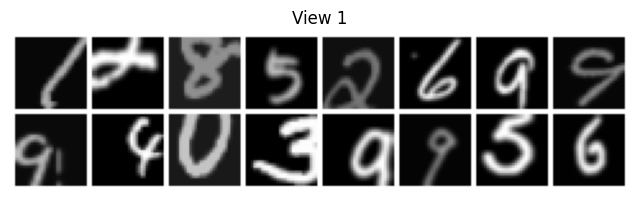

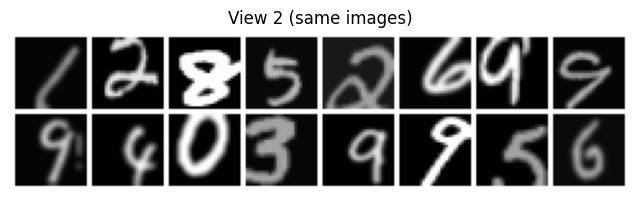

In [17]:
ssl_transform = v2.Compose([
    v2.ToImage(),
    v2.RandomResizedCrop(28, scale=(0.4, 1.0)),
    v2.RandomApply([v2.ColorJitter(brightness=0.4, contrast=0.4)], p=0.8),
    v2.RandomApply([v2.GaussianBlur(kernel_size=3, sigma=(0.1, 2.0))], p=0.5),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((MEAN,), (STD,)),
])

view_1 = [ssl_transform(img) for img in images[:16]]
view_2 = [ssl_transform(img) for img in images[:16]]

for title, views in [("View 1", view_1), ("View 2 (same images)", view_2)]:
    plt.figure(figsize=(8, 2.5))
    plt.axis("off")
    plt.title(title)
    plt.imshow(torchvision.utils.make_grid(views, padding=2, pad_value=1.0, normalize=True).permute(1, 2, 0))
    plt.show()

## 9. Using the transforms for training
The transform goes into the `Dataset`, so every image gets a new random augmentation each epoch. The test set always uses `test_transform`.

In [18]:
train_dataset = DATASET(root="./data", train=True, download=True, transform=train_transform)
test_dataset = DATASET(root="./data", train=False, download=True, transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

images, labels = next(iter(train_loader))
print(images.shape, f"mean = {images.mean():.2f}, std = {images.std():.2f}")

torch.Size([64, 1, 28, 28]) mean = 0.06, std = 0.96


## References
* Chen, T., Kornblith, S., Norouzi, M., & Hinton, G. (2020). A simple framework for contrastive learning of visual representations. *ICML*.
* Cubuk, E. D., Zoph, B., Mané, D., Vasudevan, V., & Le, Q. V. (2019). AutoAugment: Learning augmentation strategies from data. *CVPR*.
* Cubuk, E. D., Zoph, B., Shlens, J., & Le, Q. V. (2020). RandAugment: Practical automated data augmentation with a reduced search space. *NeurIPS*.
* Hendrycks, D., Mu, N., Cubuk, E. D., Zoph, B., Gilmer, J., & Lakshminarayanan, B. (2020). AugMix: A simple data processing method to improve robustness and uncertainty. *ICLR*.
* Müller, S. G., & Hutter, F. (2021). TrivialAugment: Tuning-free yet state-of-the-art data augmentation. *ICCV*.
* Simard, P. Y., Steinkraus, D., & Platt, J. C. (2003). Best practices for convolutional neural networks applied to visual document analysis. *ICDAR*.
* Yun, S., Han, D., Oh, S. J., Chun, S., Choe, J., & Yoo, Y. (2019). CutMix: Regularization strategy to train strong classifiers with localizable features. *ICCV*.
* Zhang, H., Cisse, M., Dauphin, Y. N., & Lopez-Paz, D. (2018). mixup: Beyond empirical risk minimization. *ICLR*.
* Zhong, Z., Zheng, L., Kang, G., Li, S., & Yang, Y. (2020). Random erasing data augmentation. *AAAI*.